# Spectra Processing for Sand SWR Project

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats
from scipy.optimize import curve_fit
import seaborn as sns
import os
import matplotlib.dates as md
from matplotlib.transforms import ScaledTranslation
import textwrap




# Random Forest
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, ConfusionMatrixDisplay
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from scipy.stats import randint

from matplotlib import cm

# # importing required libraries
# from mpl_toolkits.mplot3d import Axes3D
# import matplotlib.pyplot as plt


compounds = {
    0:'Empty Boat',
    1:'Palmitic Acid',
    3:'Oleic Acid',
    4:'Linoleic Acid',
    5:'Stearamide',
    6:'Oleamide',
    7:'n-Octadecane',
    8:'1-Tetradecene',
    10:'1-Docosanol',
    11:'Abietic acid',
    12:'Squalene',
    13:'Humic acid',
    14:'Fulvic acid',
    15:'Lignin',
    16:'Nordihydroguaiaretic acid (NDGA)',
    17:'Sucrose',
    18:'Fructose',
    19:'Blank',
    20:'Methanol Blank',
    21:'Hexane Blank',
    22:'NaOH Blank',
    23:'Water Blank'
               }

temperatures = {
    'A':25, # Room temperature
    'B':150,
    'C':200,
    'D':250,
    'E':275,
    'F':300,
    'G':350
}

In [40]:
def mean_std_col(df):
    """Creates a mean and standard deviation column in the given dataframe from all data columns

    Args:
        df (pd.DataFrame): input dataframe

    Returns:
        pd.DataFrame: the same dataframe with an added mean and std columns
    """
    df_dropped = df.copy()

    if 'mean' in df_dropped.keys().tolist():
        df_dropped = df_dropped.drop(columns=['mean'])
    if 'std' in df_dropped.keys().tolist():
        df_dropped = df_dropped.drop(columns=['std'])
    
    mean_col = df_dropped.mean(axis=1)
    std_col = df_dropped.std(axis=1)

    if len(df_dropped.keys()) < 2:
        std_col[:] = np.nan

    df_dropped['mean'] = mean_col
    df_dropped['std'] = std_col

    return df_dropped


def drop_rows(df):
    """Sets the x range for mean and std columns of the given data frame. Use for graphing 

    Args:
        df (pd.Dataframe): input dataframe
    """   
    try: 
        dr1 = np.arange(1820,1933,1).tolist()
        dr2 = np.arange(2452,2501,1).tolist()
        dr3 = np.arange(1355,1408,1).tolist()
        dr = dr1 + dr2 + dr3
        for row in dr:
            df.loc[row] = np.nan

        df.reindex(pd.Index(np.arange(350,2501,1)), name='Wavelength')
    except:
        1
        # print("There are no mean or std columns in the dataframe")

def drop_all_rows(df):
    """Sets the x range for all columns of the given data frame. Use for regression or stat analysis

    Args:
        df (pd.Dataframe): input dataframe
    """   
    try: 
        # pd.options.mode.chained_assignment = None  # Disable the warning
        dr1 = np.arange(1820,1933,1).tolist()
        dr2 = np.arange(2452,2501,1).tolist()
        dr3 = np.arange(1355,1408,1).tolist()
        dr = dr1 + dr2 + dr3
        for row in dr:
            df.loc[row] = np.nan
        df = df.dropna()
        # pd.options.mode.chained_assignment = 'warn' # Re-enable the warning (default)

        return df

    except:
        print()

def wavelength_to_rgb(wavelength, gamma=0.8):
  """Converts a wavelength in nm (380-750) to an approximate RGB tuple (0-1)."""
  wavelength = float(wavelength)
  if 340 <= wavelength <= 440:
    R = -(wavelength - 440) / (440 - 340)
    G = 0.0
    B = 1.0
  elif 440 < wavelength <= 510:
    R = 0.0
    G = (wavelength - 440) / (510 - 440)
    B = 1.0
  elif 510 < wavelength <= 580:
    R = 0.0
    G = 1.0
    B = -(wavelength - 580) / (580 - 510)
  elif 580 < wavelength <= 645:
    R = (wavelength - 580) / (645 - 580)
    G = 1.0
    B = 0.0
  elif 645 < wavelength <= 780:
    R = 1.0
    G = -(wavelength - 780) / (780 - 645)
    B = 0.0
  else:
    R, G, B = 0.0, 0.0, 0.0

  # Let intensity fall off near the vision limits
  if 380 <= wavelength < 420:
    factor = 0.3 + 0.7 * (wavelength - 380) / (420 - 380)
  elif 700 < wavelength <= 750:
    factor = 0.3 + 0.7 * (750 - wavelength) / (750 - 700)
  else:
    factor = 1.0

  R = (R * factor) ** gamma
  G = (G * factor) ** gamma
  B = (B * factor) ** gamma
  return (R, G, B)




## Read Reflectance Spectra

In [2]:
filename=r"C:\Users\nmmas\OneDrive - Desert Research Institute\WDPT Sand SWR\20261027 Reflectance\all_spectra_removed.csv"
df = pd.read_csv(filename, index_col=0,dtype=float)

# mask = (df > 1)
# df = df[mask].dropna(how='all', axis=1)
df

,11-B.000,11-B.001,11-B.002,11-B.003,11-B.004,11-B.005,11-B.006,11-B.007,11-C.000,11-C.002,...,8-F.004,8-F.005,8-F.006,8-G.000,8-G.001,8-G.002,8-G.003,8-G.004,8-G.005,8-G.006
Wavelength,,,,,,,,,,,,,,,,,,,,,
350.0,0.121948,0.117086,0.118481,0.113113,0.119844,0.120154,0.124162,0.125401,0.090877,0.096770,...,0.240108,0.235744,0.230879,0.194007,0.171999,0.170754,0.166384,0.179035,0.186606,0.187224
351.0,0.124196,0.118979,0.120000,0.114968,0.122606,0.121428,0.125863,0.126668,0.091431,0.097041,...,0.240608,0.236931,0.232343,0.196070,0.172622,0.170273,0.166737,0.180750,0.187053,0.188014
352.0,0.125833,0.120861,0.122236,0.117071,0.124466,0.123374,0.128153,0.128785,0.092326,0.098073,...,0.242063,0.238040,0.233620,0.197136,0.173250,0.171172,0.167877,0.181678,0.188210,0.188913
353.0,0.127459,0.122679,0.124270,0.118914,0.126389,0.125474,0.130341,0.131293,0.093567,0.099339,...,0.243954,0.239653,0.234982,0.197325,0.173982,0.172604,0.168812,0.182299,0.189674,0.190022
354.0,0.129604,0.124359,0.125591,0.120290,0.128976,0.127179,0.131939,0.133389,0.094778,0.100178,...,0.245524,0.241803,0.236567,0.197610,0.174813,0.173481,0.168965,0.183163,0.190845,0.191180
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2496.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2497.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2498.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Format Reflectance Spectra for various analysis

In [3]:
keys = df.keys().to_list()
# keys = [x.replace('.','-') for x in keys]
keys_split = [x.split('.')[0] for x in keys]
compounds_split = [x.split('-')[0] for x in keys_split]
temps_split = [x.split('-')[1] for x in keys_split]

keys_to_c_t = dict(zip(keys,keys_split))
keys_to_c = dict(zip(keys,compounds_split))
keys_to_t = dict(zip(keys,temps_split))



df_T = df.T.reset_index()

df_T['C-T'] = df_T['index'].map(keys_to_c_t)
df_T.set_index('index', inplace=True)

sorted_df = {k: v.drop(columns=['C-T']).T for k, v in df_T.groupby('C-T')}



df_T = df.T.reset_index()

df_T['C'] = df_T['index'].map(keys_to_c)
df_T.set_index('index', inplace=True)

sorted_c_dict = {k: v.drop(columns=['C']).T for k, v in df_T.groupby('C')}



df_T = df.T.reset_index()

df_T['T'] = df_T['index'].map(keys_to_t)
df_T.set_index('index', inplace=True)

sorted_t_dict = {k: v.drop(columns=['T']).T for k, v in df_T.groupby('T')}






sorted_mean_dict = {}
single_means = {}
folder_name = r"C:\Users\nmmas\OneDrive - Desert Research Institute\WDPT Sand SWR\20261027 Reflectance"

for key, data in sorted_df.items():
    df_ = data.copy()
    mean = data.mean(axis=1)
    df_['Mean'] = mean
    df_['std'] = data.std(axis=1)
    
    sorted_mean_dict[key] = df_
    single_means[key] = mean

    # df_.to_csv(folder_name+rf'\{key}.csv')


sorted_spectra_means = {}

for key, data in sorted_df.items():
    mean = data.mean(axis=0)
    index = [x.split('.')[-1] for x in mean.index.to_list()]
    index = dict(zip(mean.index.to_list(),index))
    sorted_spectra_means[key] = mean.rename(index=index)






single_means_df = pd.DataFrame.from_dict(single_means)

keys_means = single_means_df.keys().to_list()
compounds_split = [x.split('-')[0] for x in keys_means]
keys_to_c = dict(zip(keys_means,compounds_split))
temps_split = [x.split('-')[1] for x in keys_means]
temps_split = [temperatures[x] for x in temps_split]
keys_to_t = dict(zip(keys_means,temps_split))

df_T = single_means_df.T.reset_index()

df_T['C'] = df_T['index'].map(keys_to_c)
df_T['T'] = df_T['index'].map(keys_to_t)
df_T.set_index('index', inplace=True)

single_means_sorted_dict = {k: v.drop(columns=['C']).set_index('T').T for k, v in df_T.groupby('C')}



df_spectral_mean = pd.DataFrame(*[sorted_spectra_means])
# df_spectral_mean = df.mean(axis=0)


df_stacked = df_spectral_mean.stack().reset_index().rename(
    {'index':'Observation','level_1':'C-T',0:'Spectral Mean'},
      axis=1)

df_stacked[['C', 'T']] = df_stacked['C-T'].str.split('-',expand=True)
df_stacked['T'] = df_stacked['T'].str.split('.', expand=True)[0]


df_stacked['Compound'] = df_stacked['C'].astype(int).map(compounds)
df_stacked['Temperature'] = df_stacked['T'].map(temperatures)

# df_stacked = df_stacked.drop(columns=['C','T'])

df_stacked

,Observation,C-T,Spectral Mean,C,T,Compound,Temperature
0,000,1-B,0.707062,1,B,Palmitic Acid,150
1,000,1-C,0.801277,1,C,Palmitic Acid,200
2,000,1-D,0.792875,1,D,Palmitic Acid,250
3,000,1-E,0.812903,1,E,Palmitic Acid,275
4,000,1-F,NaN,1,F,Palmitic Acid,300
...,...,...,...,...,...,...,...
787,1,8-C,NaN,8,C,1-Tetradecene,200
788,1,8-D,NaN,8,D,1-Tetradecene,250
789,1,8-E,NaN,8,E,1-Tetradecene,275
790,1,8-F,NaN,8,F,1-Tetradecene,300


## Spectral Means

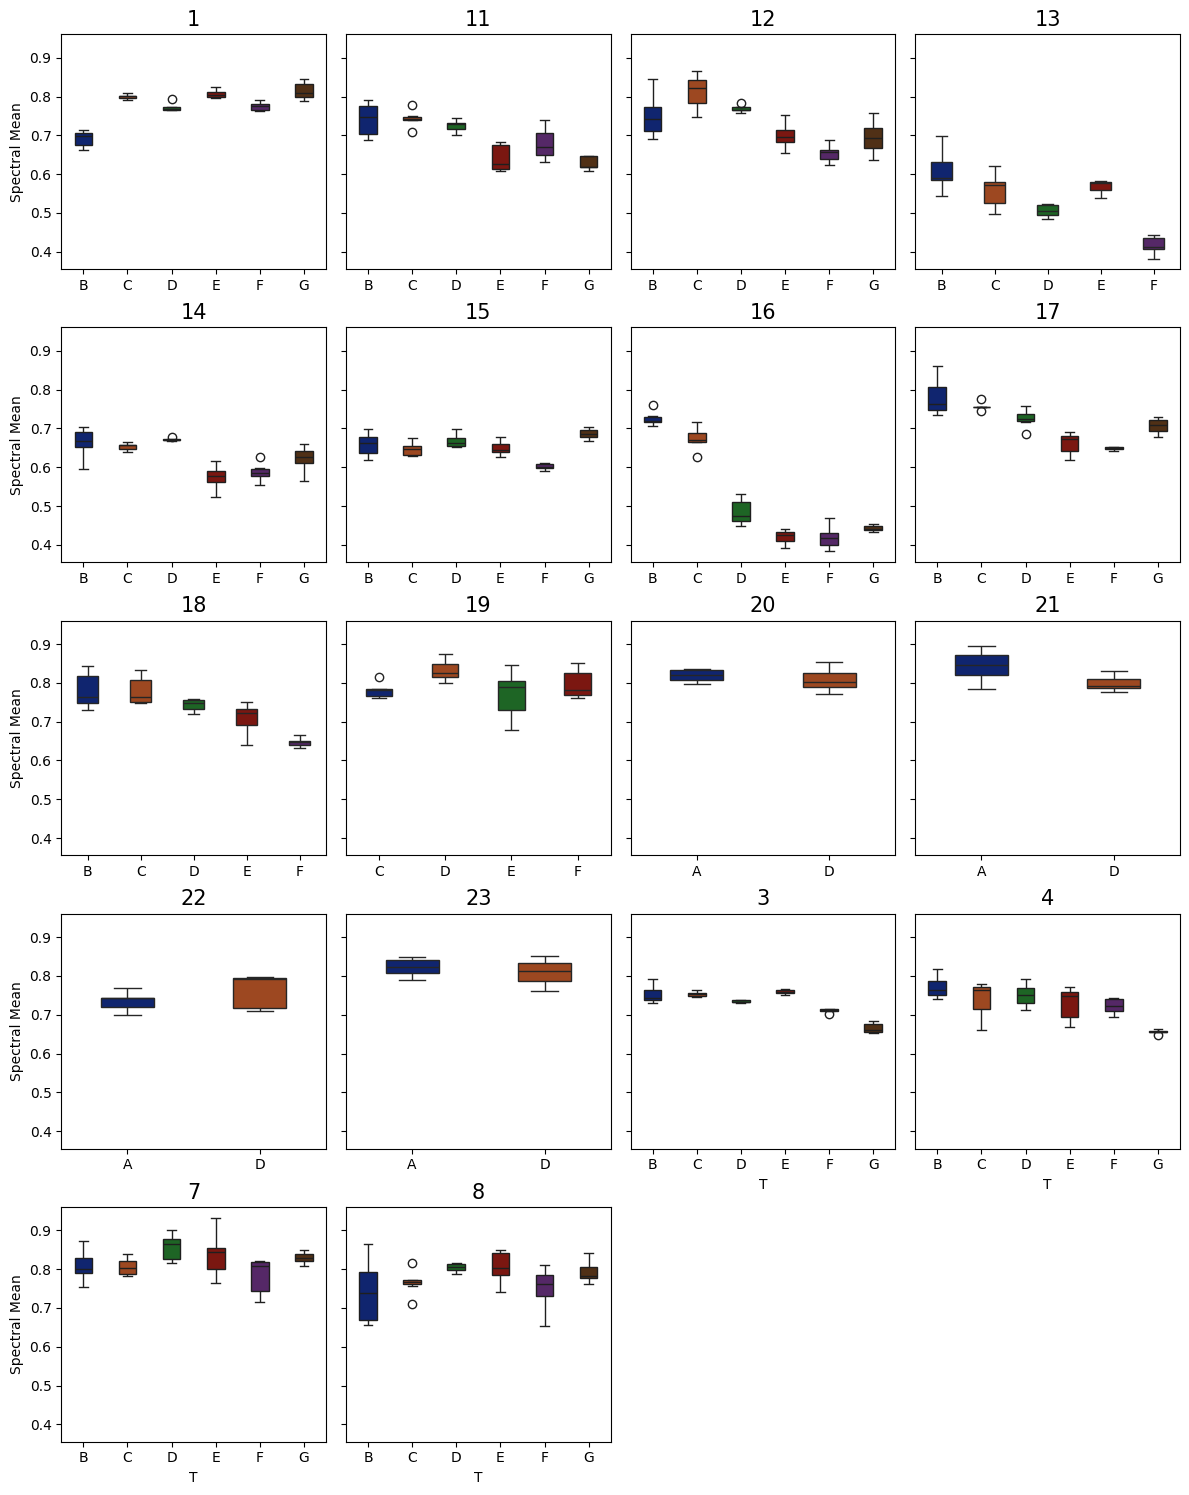

In [21]:
mask = ~(df_stacked['Compound'].str.contains('Empty'))

g = sns.FacetGrid(df_stacked[mask], col='C', margin_titles=True, despine=False, sharex=False,
                  col_wrap=4)

g.map_dataframe(sns.boxplot,x="T",
            y="Spectral Mean",
            hue="T", #hue_order=['Surface','3 cm','6 cm'],
            palette='dark',
            width=0.4, #ax=ax,
            #  whis=(0, 100)
            )

g.set_titles(row_template="{row_name}", col_template="{col_name}", size=15)


# sns.stripplot(dodge=True,jitter=False,
#     data=scatter_data,
#     x="Date",
#     y="Max Temp",
#     hue="Depth",hue_order=['Surface','3 cm','6 cm'],
#     palette=colors,
#     s=8,
#     linewidth=1,      
#     edgecolor="k", 
# )

## Graph Spectra

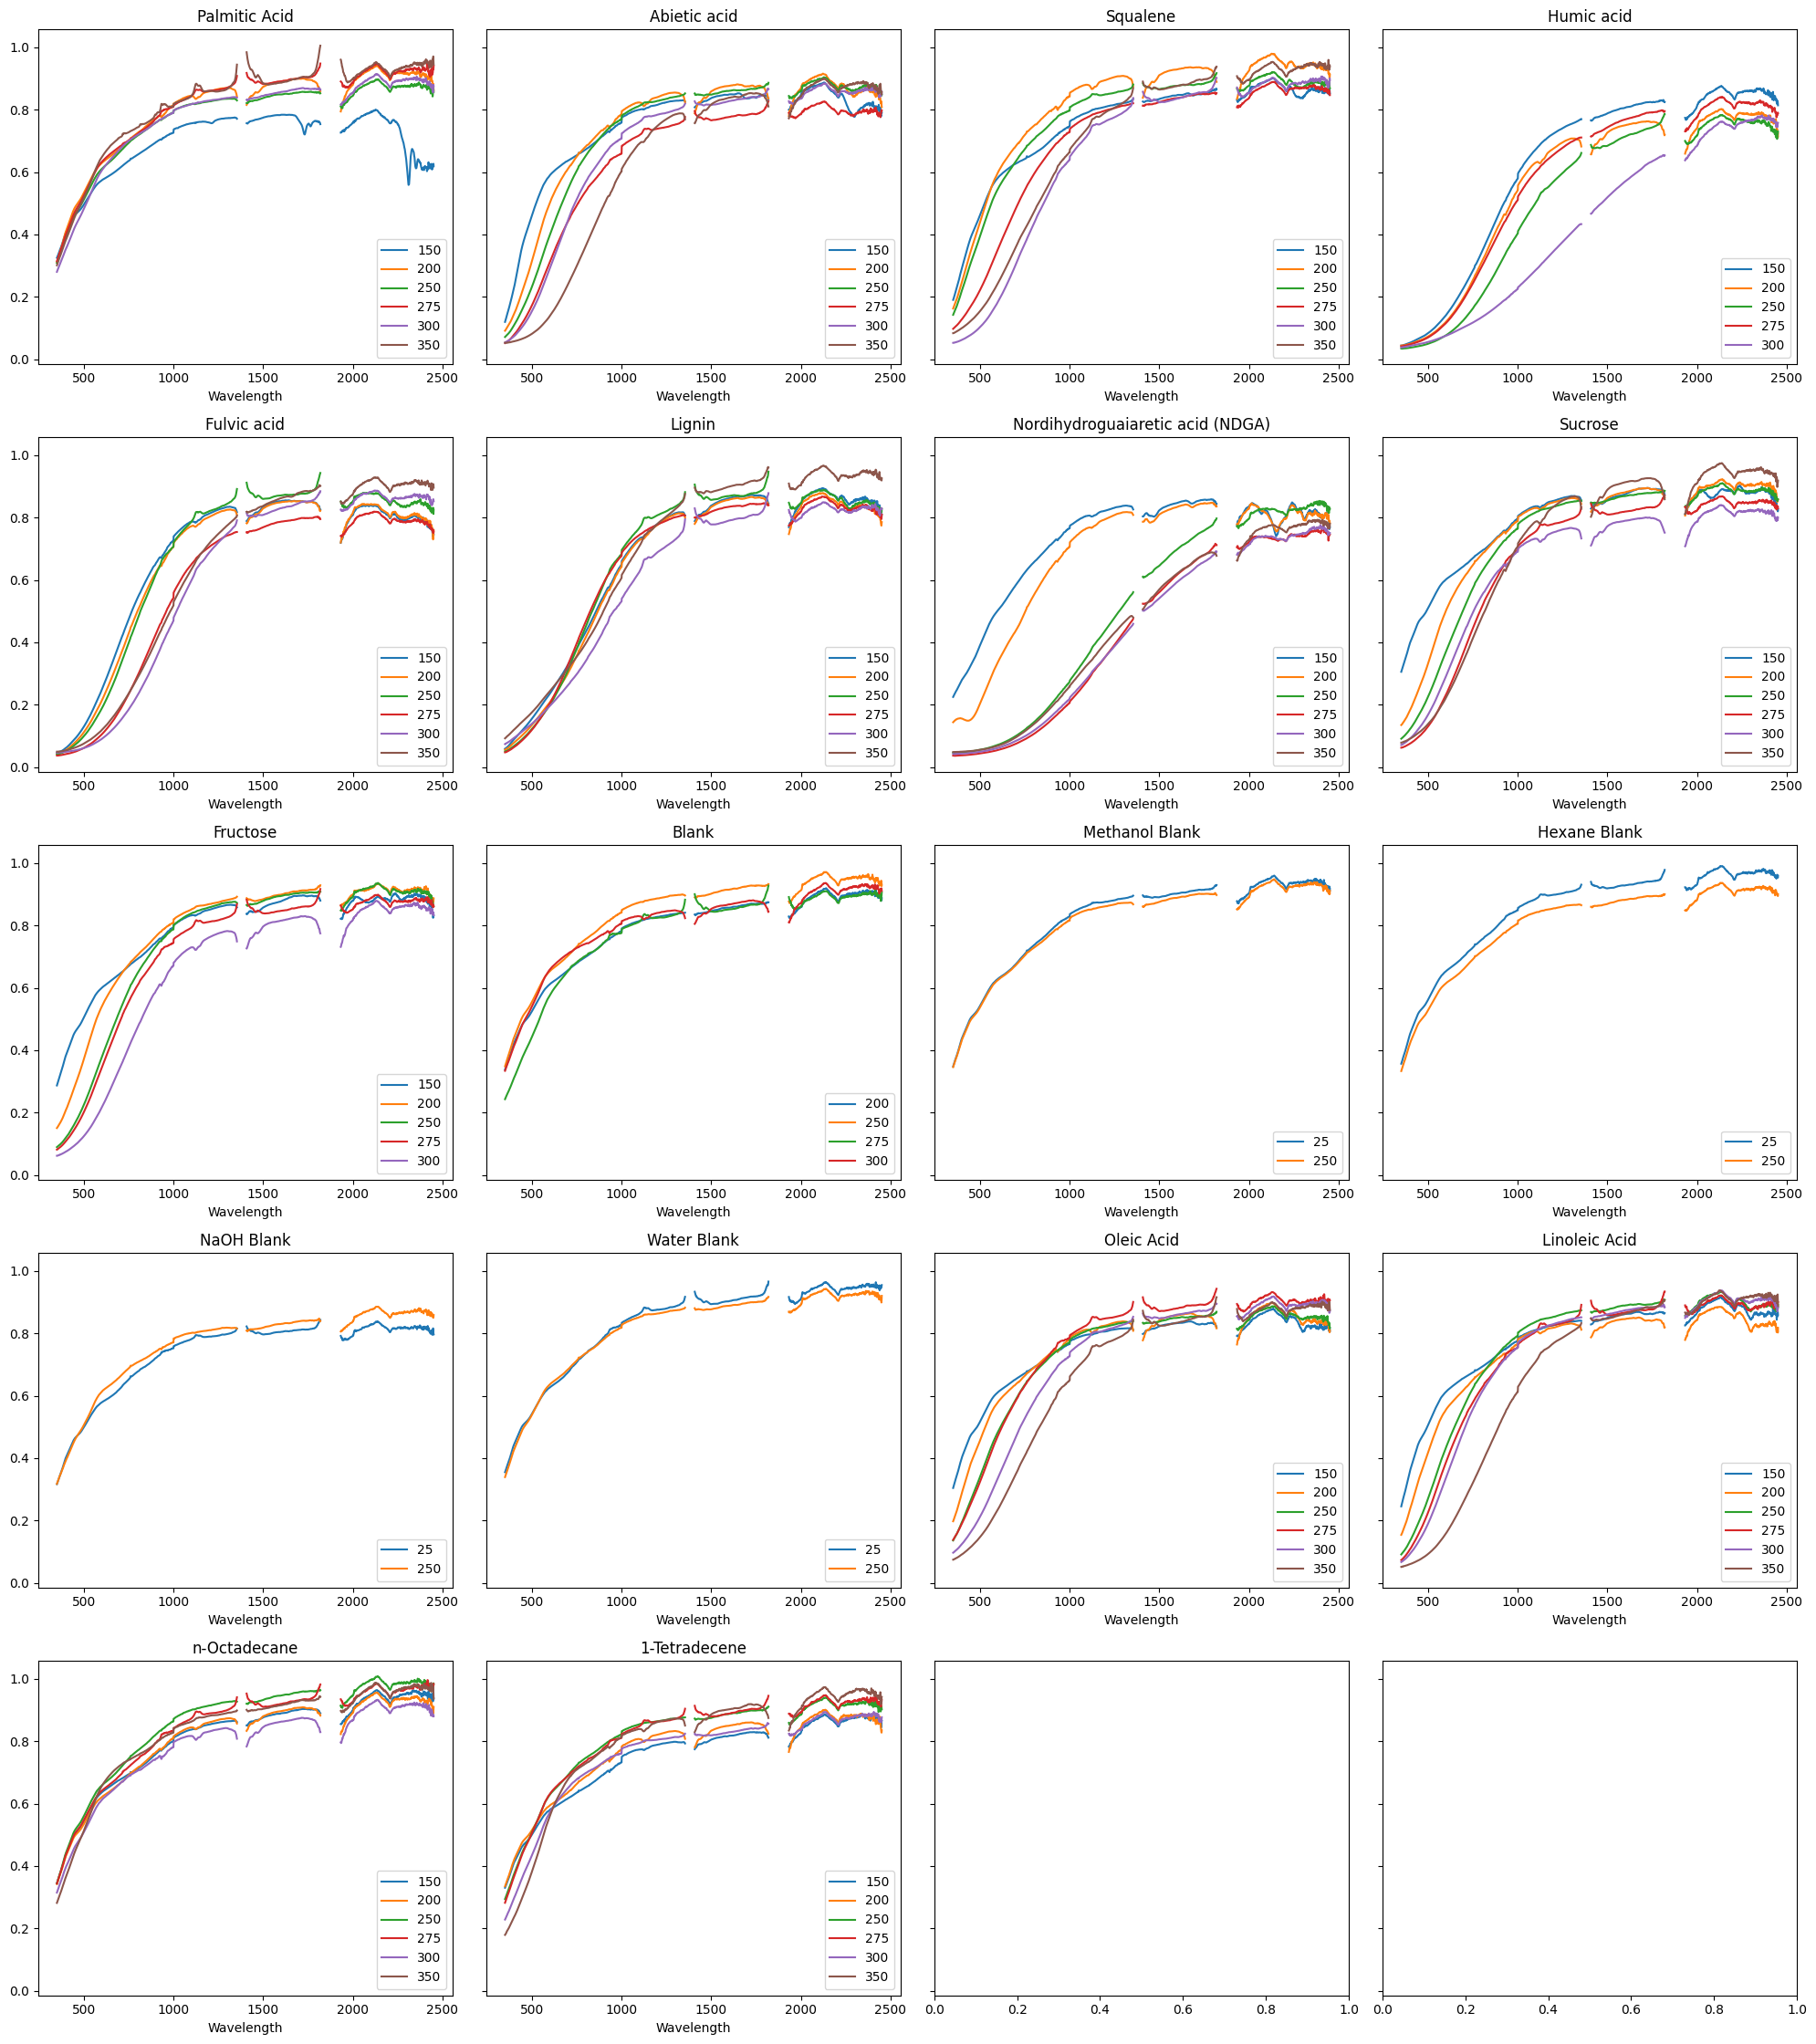

In [ ]:
n = len(single_means_sorted_dict.keys())
ncols = 4
nrows = int(np.ceil(n/ncols))

fig,axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(5 * ncols, 4.5 * nrows), sharey=True)
axes_flat = axes.flatten()
i=0
for key, item in single_means_sorted_dict.items():
    ax = axes_flat[i]
    item.index = item.index.astype(int)
    item.plot(ax=ax)
    ax.set_title(compounds[int(key)])
    ax.legend(loc='lower right')
    # item.to_csv(folder_name+rf'\{compounds[int(key)]}_means.csv')

    i+=1

plt.tight_layout()
# fig.savefig(r"C:\Users\nmmas\OneDrive - Desert Research Institute\WDPT Sand SWR\means_removed.png", dpi=300)

plt.show()

    

## Temperature versus Reflectance Contour Plots

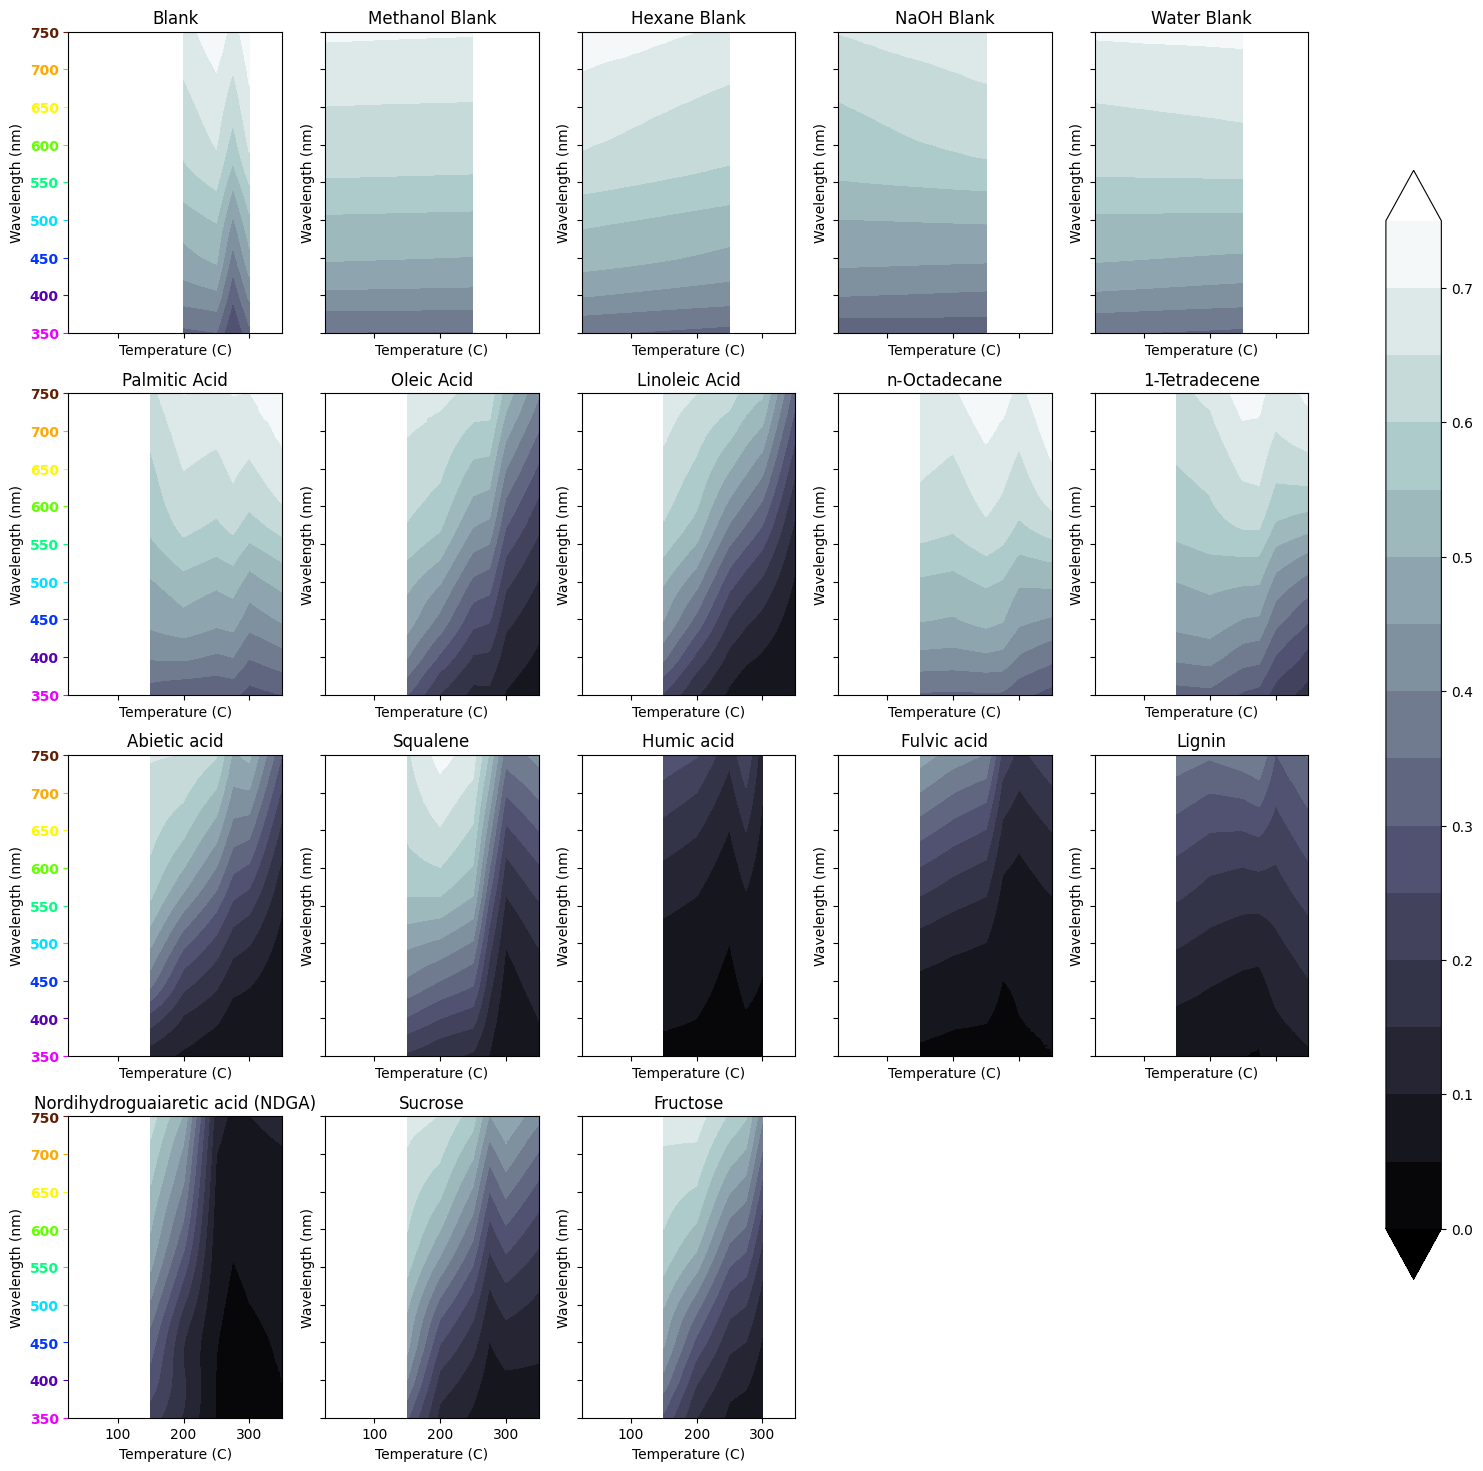

In [ ]:
order = ['19','20','21','22','23',
         '1','3','4','7','8',
         '11','12','13','14','15',
         '16','17','18',
         ]

dict_o = {key:single_means_sorted_dict[key] for key in order}

dict_o = {key:item.loc[350:750] for key,item in dict_o.items()}




n = len(dict_o.keys())
ncols = 5
nrows = int(np.ceil(n/ncols))

import numpy as np
from matplotlib.colors import Normalize
import matplotlib.pyplot as plt
import matplotlib.cm as cm

# fig, axes = plt.subplots(nrows=2, ncols=2)
# cmap = cm.get_cmap('bone')
# normalizer = Normalize(0, 4)
# im = cm.ScalarMappable(norm=normalizer)

fig,axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(4 * ncols, 4.5 * nrows), sharey=True, sharex=True)
axes_flat = axes.flatten()
i=0
for key, data_df in dict_o.items():
    ax = axes_flat[i]

    X = np.array(data_df.keys().to_list())
    Y = data_df.index.to_numpy(dtype=float)

    X, Y = np.meshgrid(X,Y)

    Z = data_df.to_numpy()

    # zmin = np.nanmin(Z)
    # zmax = np.nanmax(Z)
    zmin=0.0
    zmax=0.8


    surf = ax.contourf(X, Y, Z, levels = np.arange(zmin,zmax,0.05), cmap='bone', extend='both')


    ax.set_xlabel('Temperature (C)')
    ax.set_ylabel('Wavelength (nm)')
    ax.set_title(compounds[int(key)])

    for tick, label in zip(ax.yaxis.get_major_ticks(), ax.get_yticklabels()):
        # Use the tick's actual data location (more reliable than parsing string text)
        wavelength = tick.get_loc()
        color_rgb = wavelength_to_rgb(int(wavelength))
        label.set_color(color_rgb)
        tick.tick1line.set_markeredgecolor(color_rgb)
        label.set_fontweight("bold")

    # ax.legend(loc='lower right')
    i+=1

fig.colorbar(surf, ax=axes.ravel().tolist(), orientation='vertical', shrink=0.8)

for j in range(n, len(axes_flat)):
    axes_flat[j].remove()  # Or: fig.delaxes(axes_flat[j])

# fig.savefig(r"C:\Users\nmmas\OneDrive - Desert Research Institute\WDPT Sand SWR\R_T_vis_contours.png", dpi=300, bbox_inches='tight')

plt.show()





## All Spectra per Boat

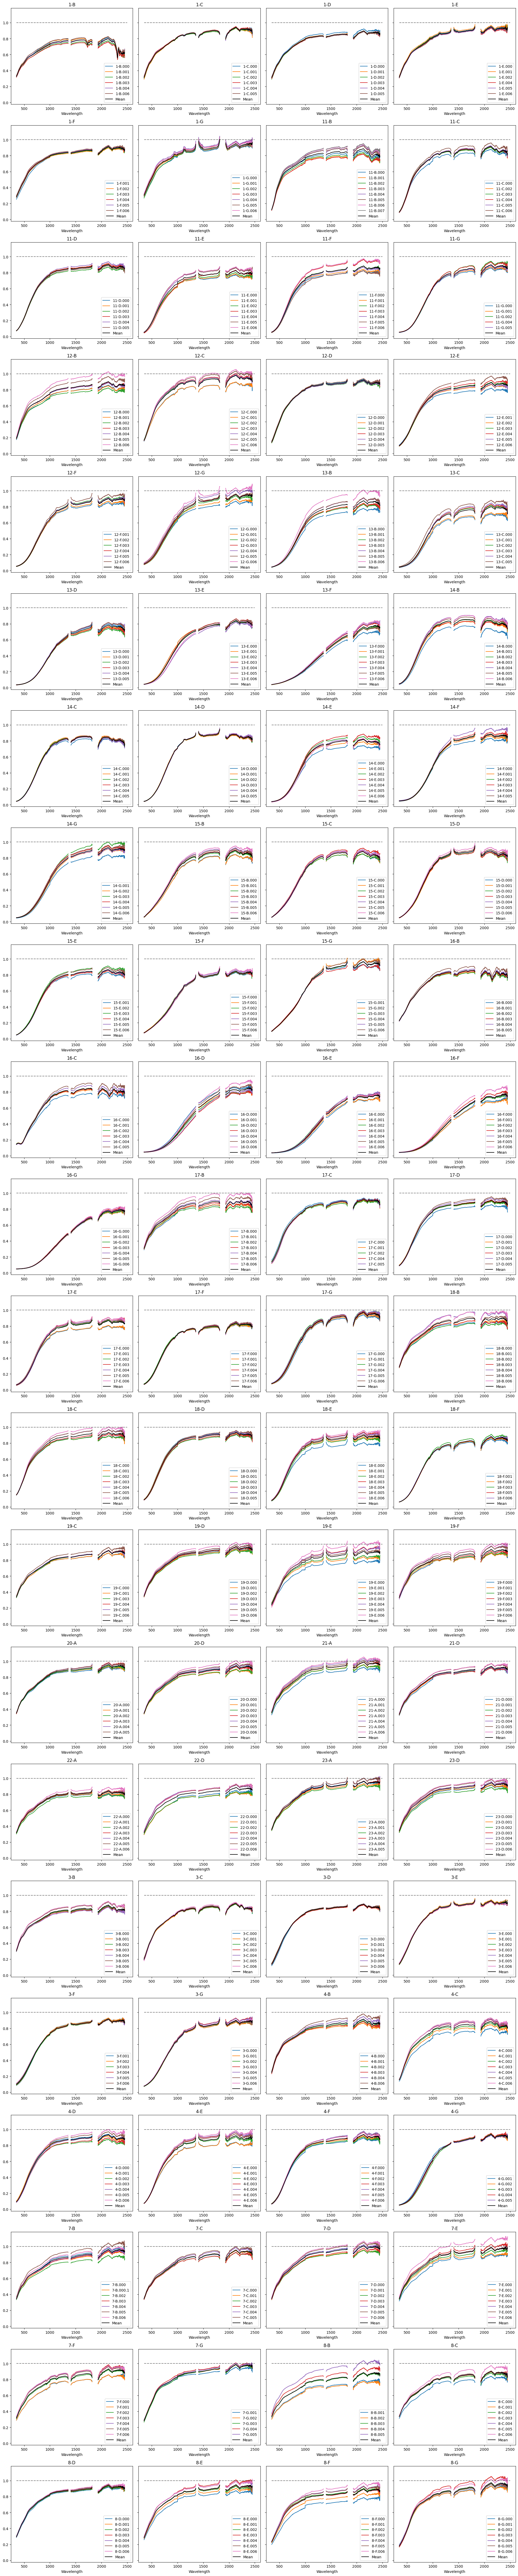

In [ ]:
n = len(sorted_mean_dict.keys())
ncols = 4
nrows = int(np.ceil(n/ncols))

fig,axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(5 * ncols, 4.5 * nrows), sharey=True)
axes_flat = axes.flatten()
i=0
for key, item in sorted_mean_dict.items():
    ax = axes_flat[i]
    item.index = item.index.astype(int)
    item.drop(columns=['std','Mean']).plot(ax=ax)
    item['Mean'].plot(ax=ax, color='k')
    ax.hlines(y=[1], xmin=350, xmax=2500, color='k', linestyles='--',alpha=0.5)
    ax.set_title(key)
    ax.legend(loc='lower right')
    i+=1

plt.tight_layout()
plt.show()


# Convolving

In [7]:

def resample_dataframe_spectra_SRF(df_spectra, source_wl, target_wl, target_srf, target_bands):
    """
    Resamples a pandas DataFrame of spectra to multiple target bands using spectral response function
    
    Parameters:
    -----------
    df_spectra : pd.DataFrame
        DataFrame of shape (N_pixels, N_source_bands). Each row is a spectrum.
        Columns should correspond sequentially to the source_wl array.
    source_wl : np.ndarray or list
        1D array of the original hyperspectral band center wavelengths.
    target_wl, target_srf : lists or arrays
        Target sensor band specifications.
        
    Returns:
    --------
    df_resampled : pd.DataFrame
        A new DataFrame with the same index as the input, containing the target bands as columns.
    """

    # 1. Align data and extract the raw numpy matrix
    source_wl = np.asarray(source_wl)
    # Ensure we drop any metadata columns if they exist, or just grab the values
    spectra_matrix = df_spectra.values  # Shape: (P, S)
    
    # 2. Read spectral response function as weights
    weights = target_srf
    
    # 4. Compute NaN-safe weighted sum
    # Instead of standard np.dot, we nullify the weights where the specific pixel has a NaN.
    # We expand spectra_matrix to (P, S, 1) and weights to (1, S, T) to broadcast across all combinations
    safe_spectra = np.nan_to_num(spectra_matrix) # Replace NaNs with 0 temporarily for multiplication
    
    # Numerator: Weighted reflectance 3D array (integral of Ref*SRF)
    # (n, M, 1) * (1, M, N) -> (n, M, N)
    weighted_ref = weights[np.newaxis,...].T * safe_spectra.T[np.newaxis,...]
    numerator = np.trapezoid(weighted_ref, axis=1)



    # Denominator: Weights for each band (integral of SRF)
    denominator = np.trapezoid(weights, axis=0)
    
    resampled_matrix = numerator / denominator[..., np.newaxis]

    # Reconstruct back into a clean Pandas DataFrame
    col_names = np.asarray(target_bands)
    df_resampled = pd.DataFrame(resampled_matrix.T, index=df_spectra.index, columns=col_names)

    return df_resampled

spectra_rfc = single_means_df.T
# spectra_rfc = pd.read_csv(r"C:\Users\nmmas\OneDrive - Desert Research Institute\WDPT Sand SWR\20261027 Reflectance\all_spectra_removed.csv",index_col=0).T
spectra_rfc

Wavelength,350.0,351.0,352.0,353.0,354.0,355.0,356.0,357.0,358.0,359.0,...,2491.0,2492.0,2493.0,2494.0,2495.0,2496.0,2497.0,2498.0,2499.0,2500.0
1-B,0.325358,0.326621,0.328085,0.329601,0.330912,0.332138,0.333903,0.335775,0.337158,0.338225,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1-C,0.311275,0.312950,0.314694,0.316560,0.318489,0.320410,0.322477,0.324675,0.326837,0.328439,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1-D,0.308737,0.310126,0.311622,0.313310,0.315079,0.316532,0.318237,0.320084,0.321768,0.323169,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1-E,0.314451,0.315888,0.317684,0.319620,0.321292,0.322667,0.324676,0.326882,0.328597,0.330033,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1-F,0.280358,0.282202,0.283721,0.285078,0.286506,0.287866,0.289590,0.291413,0.292929,0.294077,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8-C,0.335022,0.336700,0.338322,0.339952,0.341605,0.343092,0.344929,0.346740,0.348129,0.349691,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8-D,0.294306,0.295949,0.297352,0.298857,0.300576,0.301670,0.303279,0.305121,0.306616,0.307933,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8-E,0.282254,0.284164,0.285814,0.287336,0.288876,0.290430,0.292205,0.294052,0.295771,0.297441,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8-F,0.228638,0.229631,0.230738,0.232076,0.233559,0.234990,0.236225,0.237440,0.238783,0.239822,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:

# ============================================ #
# Create .csv for convolved SRF type sensors   #
# ============================================ #


SRF_names = [
    'Sentinel-2A SRF',
    'Sentinel-2B SRF',
    'Sentinel-2C SRF',
    'Landsat ETM+ SRF',
    'Landsat 9 OLI SRF',
]

for srf_name in SRF_names:

    # # Target SRF for Spectral Response type sensors
    target_srf = pd.read_excel(r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\SRFs\CommonSensors.xlsx",
                            sheet_name=srf_name, index_col='Wavelength')


    src_wl = spectra_rfc.rename(columns=(int)).T.index
    src_spectra = spectra_rfc.rename(columns=(int))

    # Define target sensor parameters (e.g., simulating a specific Sentinel or Landsat band)
    target_wl = target_srf.index.to_list()          # Center wavelength (nm)
    target_srf_vals = target_srf.values             # SRF
    target_bands = target_srf.keys().to_list()      # Name of bands


    # Execute resampling
    band_value = resample_dataframe_spectra_SRF(
            source_wl=src_wl,
            df_spectra=src_spectra,
            target_wl=target_wl,
            target_srf=target_srf_vals,
            target_bands=target_bands
        ).T

    # plt.plot(src_wl, src_spectra.iloc[0])

    # plt.plot(target_wl, band_value.T[0,:,0])
    # plt.plot(target_wl, band_value.T[0,:,1])
    # plt.plot(target_wl, band_value.T[0,:,2])
    # plt.plot(target_wl, band_value.T[0,:,3])
    # plt.plot(target_wl, band_value.T[0,:,4])
    # plt.plot(target_wl, band_value.T[0,:,5])
    # plt.plot(target_wl, band_value.T[0,:,6])
    # plt.plot(target_wl, band_value.T[0,:,7])
    # plt.plot(target_wl, band_value.T[0,:,8])
    # plt.plot(target_wl, band_value.T[0,:,9])
    # plt.plot(target_wl, band_value.T[0,:,10])
    # plt.plot(target_wl, band_value.T[0,:,11])
    # plt.plot(target_wl, band_value.T[0,:,12])




    fname = rf"C:\Users\nmmas\OneDrive - Desert Research Institute\WDPT Sand SWR\20261027 Reflectance\Resampled_means_{srf_name[:-4]}.csv"
    band_value.index.name = srf_name[:-4] + " Bands"
    # band_value.insert(loc=0, column='Category', value=spectra_rfc['Category'])
    band_value.to_csv(fname)


band_value

,1-B,1-C,1-D,1-E,1-F,1-G,11-B,11-C,11-D,11-E,...,7-D,7-E,7-F,7-G,8-B,8-C,8-D,8-E,8-F,8-G
Landsat 9 OLI Bands,,,,,,,,,,,,,,,,,,,,,
Band 1 - Ultra Blue (coastal/aerosol),0.456367,0.477257,0.454753,0.463557,0.413851,0.446645,0.354302,0.211741,0.156097,0.112997,...,0.505974,0.495757,0.452902,0.434262,0.459925,0.472661,0.438829,0.433384,0.358608,0.294195
Band 2 - Blue,0.482956,0.515674,0.494314,0.506000,0.461121,0.495960,0.430221,0.281775,0.207949,0.153478,...,0.542764,0.531009,0.491480,0.488919,0.487516,0.501608,0.486530,0.483899,0.411372,0.353955
Band 3 - Green,0.550268,0.600291,0.578690,0.597187,0.561628,0.600678,0.552493,0.436754,0.334048,0.256403,...,0.628143,0.611949,0.577346,0.605240,0.555883,0.570302,0.587609,0.587782,0.522490,0.492791
Band 4 – Red,0.592873,0.653379,0.637828,0.661061,0.643511,0.687063,0.617954,0.567241,0.481013,0.386180,...,0.684555,0.666013,0.639006,0.697110,0.599704,0.615088,0.661874,0.664655,0.617516,0.630862
Band 5 – NIR,0.680347,0.755579,0.742950,0.749706,0.742752,0.762898,0.700972,0.719219,0.699102,0.585214,...,0.800838,0.771648,0.728858,0.776820,0.678227,0.715619,0.771266,0.759330,0.718950,0.756287
Band 6 – SWIR 1,0.782980,0.890559,0.849139,0.891617,0.856911,0.887603,0.848608,0.877020,0.860663,0.777271,...,0.947109,0.920241,0.862761,0.916179,0.817450,0.850549,0.887926,0.889544,0.828938,0.902810
Band 7 – SWIR 2,0.761837,0.919463,0.877775,0.923665,0.894023,0.931011,0.844753,0.881457,0.878875,0.800511,...,0.987632,0.963676,0.911854,0.965256,0.869036,0.881910,0.920560,0.926852,0.874686,0.951640
Band 8 – Panchromatic,0.563780,0.617205,0.598137,0.618468,0.589738,0.630686,0.573180,0.481640,0.386152,0.302742,...,0.646248,0.629427,0.597923,0.636983,0.569925,0.584623,0.612649,0.613990,0.555514,0.541790


In [10]:
s2a = pd.read_csv(rf"C:\Users\nmmas\OneDrive - Desert Research Institute\WDPT Sand SWR\20261027 Reflectance\Resampled_Sentinel-2A.csv", index_col=0).T
s2a

Sentinel-2A Bands,S2A_SR_AV_B1,S2A_SR_AV_B2,S2A_SR_AV_B3,S2A_SR_AV_B4,S2A_SR_AV_B5,S2A_SR_AV_B6,S2A_SR_AV_B7,S2A_SR_AV_B8,S2A_SR_AV_B8A,S2A_SR_AV_B9,S2A_SR_AV_B11,S2A_SR_AV_B12
11-B.000,0.353628,0.444852,0.545325,0.613423,0.631483,0.647754,0.664790,0.685176,0.698810,0.726904,0.828791,0.823916
11-B.001,0.335007,0.420329,0.512552,0.576027,0.592766,0.608961,0.626301,0.646263,0.659519,0.686693,0.789812,0.786093
11-B.002,0.342981,0.432899,0.530705,0.597017,0.612980,0.627427,0.644239,0.664348,0.677631,0.704486,0.804212,0.799115
11-B.003,0.329562,0.417351,0.512447,0.577549,0.593118,0.607324,0.623948,0.643747,0.656866,0.684518,0.780689,0.781296
11-B.004,0.362626,0.463646,0.576243,0.651634,0.664078,0.673531,0.686741,0.708205,0.723242,0.762054,0.889764,0.884321
...,...,...,...,...,...,...,...,...,...,...,...,...
8-G.002,0.281325,0.356760,0.476549,0.631074,0.671087,0.697107,0.716514,0.737528,0.751867,0.779175,0.895920,0.941238
8-G.003,0.280358,0.360309,0.488913,0.659362,0.702914,0.729818,0.749103,0.771987,0.788076,0.823499,0.968494,1.026396
8-G.004,0.291250,0.366455,0.484831,0.634403,0.672050,0.696039,0.714059,0.734541,0.748604,0.777098,0.888982,0.937627
8-G.005,0.303140,0.378749,0.497013,0.641976,0.677834,0.700544,0.716655,0.736087,0.749541,0.776977,0.890121,0.934361


# NBR

In [16]:
nbr = (s2a['S2A_SR_AV_B8'] - s2a['S2A_SR_AV_B12'] / s2a['S2A_SR_AV_B8'] + s2a['S2A_SR_AV_B12'])
nbr.rename('NBR').to_csv(r"C:\Users\nmmas\OneDrive - Desert Research Institute\WDPT Sand SWR\20261027 Reflectance\NBR.csv")

In [10]:
nbr = pd.read_csv(r"C:\Users\nmmas\OneDrive - Desert Research Institute\WDPT Sand SWR\20261027 Reflectance\NBR.csv", index_col=0)

In [13]:
# keys_means = nbr.keys().to_list()
# compounds_split = [x.split('-')[0] for x in keys_means]
# keys_to_c = dict(zip(keys_means,compounds_split))
# temps_split = [x.split('-')[1] for x in keys_means]
# temps_split = [temperatures[x] for x in temps_split]
# keys_to_t = dict(zip(keys_means,temps_split))


# nbr['C'] = nbr['index'].map(keys_to_c)
# nbr['T'] = nbr['index'].map(keys_to_t)
# nbr.set_index('index', inplace=True)

# nbr

nbr['C-T'] = [x.split('.')[0] for x in nbr.index.to_list()]


nbr[['C', 'T']] = nbr['C-T'].str.split('-',expand=True)
nbr['T'] = nbr['T'].str.split('.', expand=True)[0]


nbr['Compound'] = nbr['C'].astype(int).map(compounds)
nbr['Temperature'] = nbr['T'].map(temperatures)

nbr

,NBR,C-T,C,T,Compound,Temperature
11-B.000,0.306605,11-B,11,B,Abietic acid,150
11-B.001,0.215990,11-B,11,B,Abietic acid,150
11-B.002,0.260606,11-B,11,B,Abietic acid,150
11-B.003,0.211374,11-B,11,B,Abietic acid,150
11-B.004,0.343846,11-B,11,B,Abietic acid,150
...,...,...,...,...,...,...
8-G.002,0.402558,8-G,8,G,1-Tetradecene,350
8-G.003,0.468833,8-G,8,G,1-Tetradecene,350
8-G.004,0.395688,8-G,8,G,1-Tetradecene,350
8-G.005,0.401085,8-G,8,G,1-Tetradecene,350


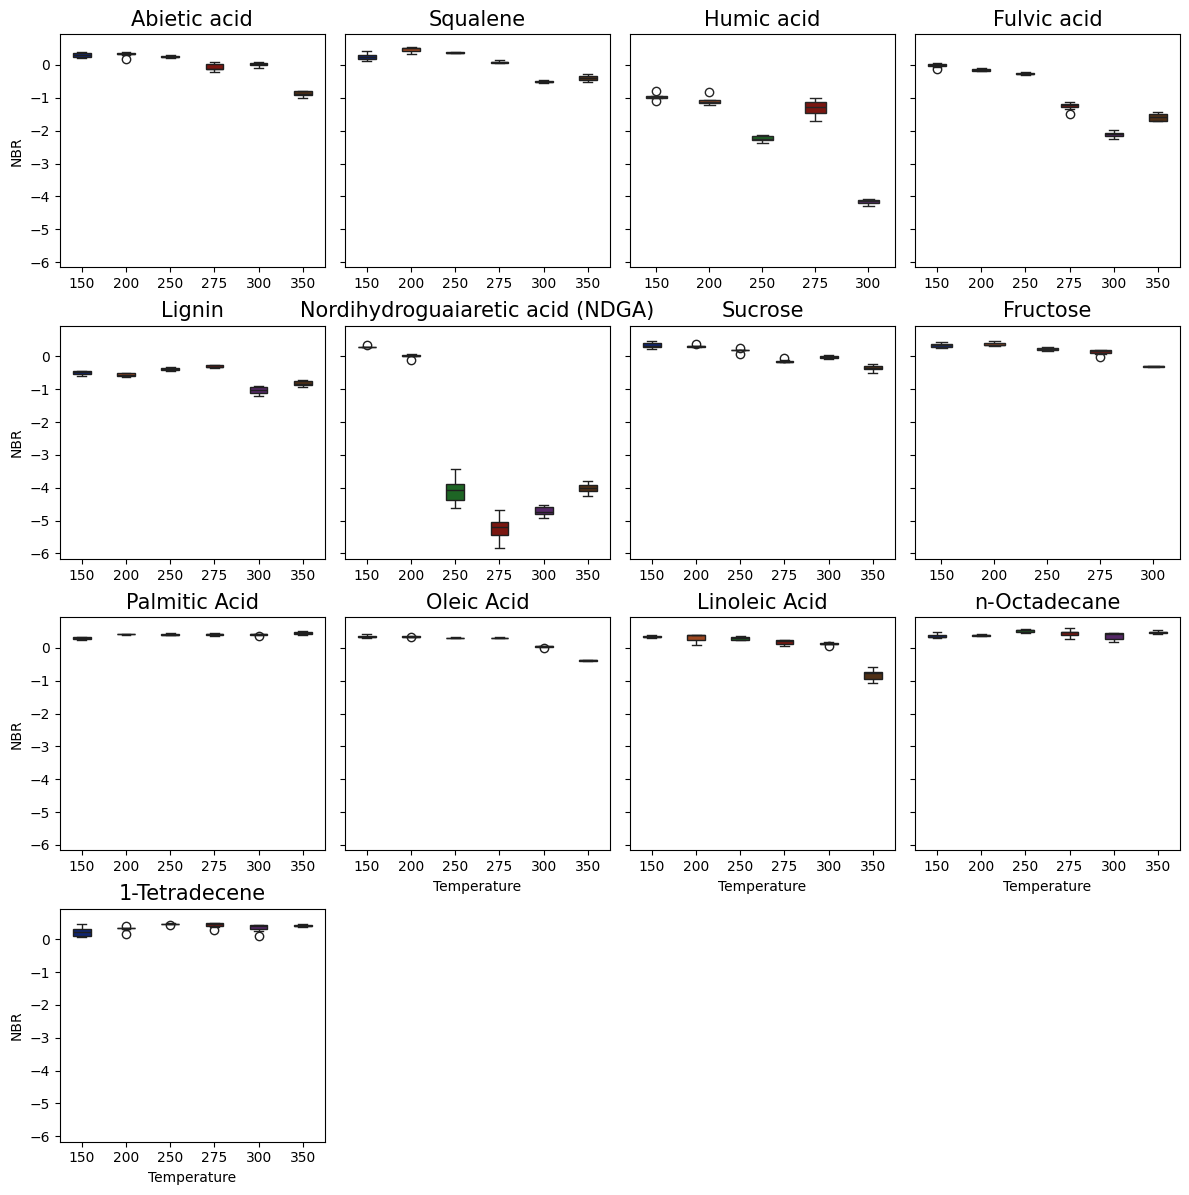

In [28]:
mask = ~(nbr['Compound'].str.contains('Blank'))

g = sns.FacetGrid(nbr[mask], col='Compound', margin_titles=True, despine=False, sharex=False,
                  col_wrap=4)

g.map_dataframe(sns.boxplot,x="Temperature",
            y="NBR",
            hue="Temperature", #hue_order=['Surface','3 cm','6 cm'],
            palette='dark',
            width=0.4, #ax=ax,
            #  whis=(0, 100)
            )

g.set_titles(row_template="{row_name}", col_template="{col_name}", size=15)